In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


In [3]:

df = pd.read_csv("uber.csv")

print(df.head())
print(df.shape)
print(df.isnull().sum())


   Unnamed: 0      key  fare_amount          pickup_datetime  \
0    24238194  52:06.0          7.5  2015-05-07 19:52:06 UTC   
1    27835199  04:56.0          7.7  2009-07-17 20:04:56 UTC   
2    44984355  45:00.0         12.9  2009-08-24 21:45:00 UTC   
3    25894730  22:21.0          5.3  2009-06-26 08:22:21 UTC   
4    17610152  47:00.0         16.0  2014-08-28 17:47:00 UTC   

   pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude  \
0        -73.999817        40.738354         -73.999512         40.723217   
1        -73.994355        40.728225         -73.994710         40.750325   
2        -74.005043        40.740770         -73.962565         40.772647   
3        -73.976124        40.790844         -73.965316         40.803349   
4        -73.925023        40.744085         -73.973082         40.761247   

   passenger_count  
0                1  
1                1  
2                1  
3                3  
4                5  
(200000, 9)
Unnamed: 0    

In [7]:

# Remove unnecessary columns
df = df.drop(['Unnamed: 0', 'key'], axis=1, errors='ignore')

# Remove missing values
df = df.dropna()

# Convert datetime
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'], utc=True)

# Extract date and time
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month

# Calculate distance
lat1 = np.radians(df['pickup_latitude'])
lon1 = np.radians(df['pickup_longitude'])
lat2 = np.radians(df['dropoff_latitude'])
lon2 = np.radians(df['dropoff_longitude'])

a = (np.sin((lat2-lat1)/2)**2 +
     np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2)

df['distance'] = 6371 * 2 * np.arcsin(np.sqrt(a))

# Remove invalid records
df = df[
    (df['fare_amount'] > 0) &
    (df['passenger_count'] > 0) &
    (df['distance'] > 0) &
    (df['distance'] < 100) &
    df['pickup_longitude'].between(-75, -72) &
    df['dropoff_longitude'].between(-75, -72) &
    df['pickup_latitude'].between(40, 42) &
    df['dropoff_latitude'].between(40, 42)
]

print("After Preprocessing:", df.shape)


After Preprocessing: (193059, 11)


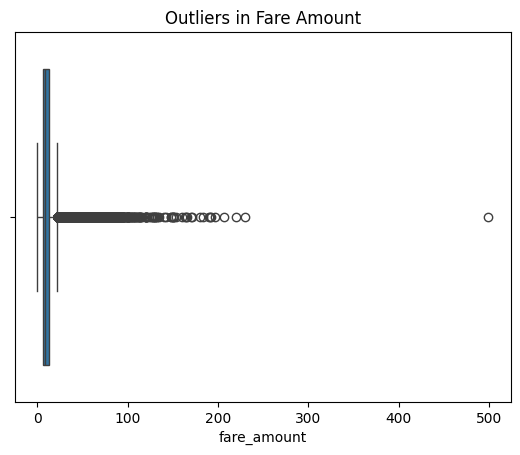

Number of Outliers: 16516


In [8]:

sns.boxplot(x=df['fare_amount'])
plt.title("Outliers in Fare Amount")
plt.show()

Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower = max(0, Q1 - 1.5 * IQR)
upper = Q3 + 1.5 * IQR

print("Number of Outliers:",
      len(df[(df['fare_amount'] < lower) |
             (df['fare_amount'] > upper)]))

df = df[
    (df['fare_amount'] >= lower) &
    (df['fare_amount'] <= upper)
]


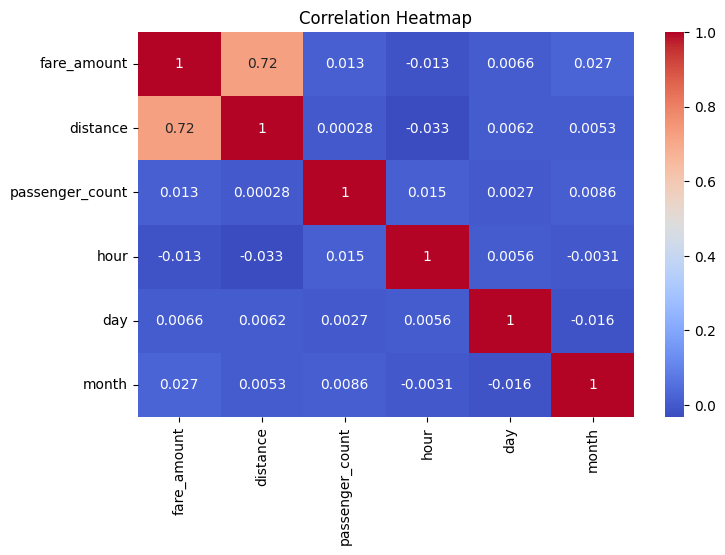

In [9]:

plt.figure(figsize=(8, 5))

sns.heatmap(
    df[['fare_amount', 'distance', 'passenger_count',
        'hour', 'day', 'month']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")
plt.show()


In [10]:

X = df[['distance', 'passenger_count', 'hour', 'day', 'month']]
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (141234, 5)
Testing Data: (35309, 5)


In [11]:

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1),
    'Lasso Regression': Lasso(alpha=0.01, max_iter=10000)
}

results = []

for name, model in models.items():

    pipeline = make_pipeline(StandardScaler(), model)

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    results.append([name, r2, rmse, mae])

    print("\n", name)
    print("R2 Score:", r2)
    print("RMSE:", rmse)
    print("MAE:", mae)



 Linear Regression
R2 Score: 0.5296330207264421
RMSE: 2.842575290287187
MAE: 1.8732415907402833

 Ridge Regression
R2 Score: 0.5296329495866285
RMSE: 2.8425755052472894
MAE: 1.8732477052231329

 Lasso Regression
R2 Score: 0.5295353959143094
RMSE: 2.8428702636731824
MAE: 1.876522460195937


In [12]:

result_df = pd.DataFrame(
    results,
    columns=['Model', 'R2 Score', 'RMSE', 'MAE']
)

print(result_df)


               Model  R2 Score      RMSE       MAE
0  Linear Regression  0.529633  2.842575  1.873242
1   Ridge Regression  0.529633  2.842576  1.873248
2   Lasso Regression  0.529535  2.842870  1.876522


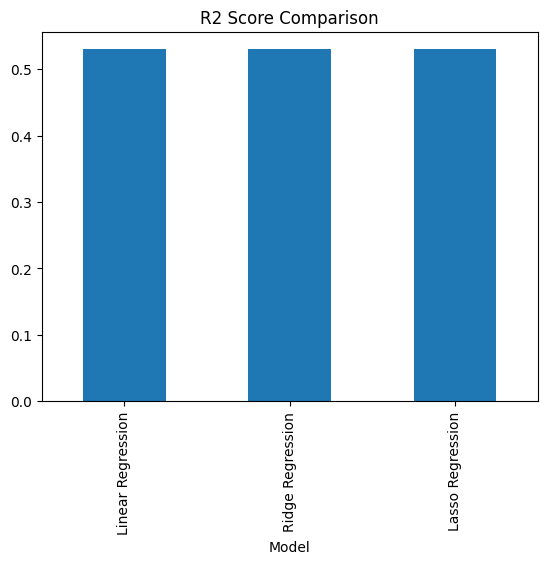

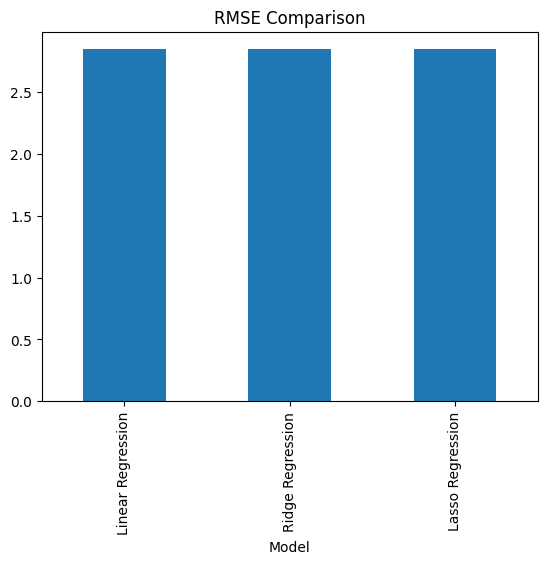

In [13]:

result_df.plot(x='Model', y='R2 Score', kind='bar',
               legend=False, title='R2 Score Comparison')
plt.show()

result_df.plot(x='Model', y='RMSE', kind='bar',
               legend=False, title='RMSE Comparison')
plt.show()
